<a href="https://colab.research.google.com/github/Kgce11harshallad/DS_PY_Writeups_2102620/blob/main/Z_Image_Turbo_Pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background-color: #161b22; padding: 20px; border-radius: 12px; border-left: 6px solid #2ecc71; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
  <h1 style="color: #ffffff; margin: 0; font-family: sans-serif; font-weight: 700; letter-spacing: 1px;">
    ⚡ Z-Image Turbo <span style="font-size: 0.6em; color: #2ecc71; vertical-align: middle; background: #2ecc7122; padding: 2px 8px; border-radius: 6px;">Pro</span>
  </h1>
  <p style="color: #8b949e; margin: 8px 0 0 0; font-family: sans-serif;">
    Next-Gen FP8 Diffusion • ComfyUI Backend • Smart Caching
  </p>
</div>

In [1]:
#@title 1. Initialize Environment
#@markdown This step installs dependencies and downloads models. <br>
#@markdown **Note:** Files are cached, so subsequent runs will be instant.

import os
import sys
from pathlib import Path
import subprocess
import time

# --- UI Logger ---
def log(msg, type="info"):
    colors = {
        "info": "\033[94m",  # Blue
        "success": "\033[92m", # Green
        "warn": "\033[93m",  # Yellow
        "error": "\033[91m", # Red
        "reset": "\033[0m"
    }
    symbols = {
        "info": "➜",
        "success": "✓",
        "warn": "⚠",
        "error": "✗"
    }
    print(f"{colors[type]}{symbols[type]} {msg}{colors['reset']}")

def run_quiet(cmd, desc):
    print(f"   ⏳ {desc}...", end="\r")
    try:
        subprocess.check_call(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        print(f"\033[92m   ✓ {desc}\033[0m    ")
    except Exception as e:
        print(f"\033[91m   ✗ {desc} Failed\033[0m")
        print(e)

# --- Paths ---
ROOT = Path("/content")
COMFY_PATH = ROOT / "ComfyUI"
MODELS_PATH = COMFY_PATH / "models"

log("Checking Environment...", "info")

# 1. Install ComfyUI
if not COMFY_PATH.exists():
    run_quiet("git clone https://github.com/comfyanonymous/ComfyUI /content/ComfyUI", "Cloning Core Repo")
    run_quiet("pip install -r /content/ComfyUI/requirements.txt", "Installing Python Dependencies")
else:
    log("ComfyUI Core found", "success")

# 2. Install Tools
run_quiet("apt -y install -qq aria2", "Installing Accelerator (Aria2)")

# 3. Download Models
model_map = [
    ("https://huggingface.co/T5B/Z-Image-Turbo-FP8/resolve/main/z-image-turbo-fp8-e4m3fn.safetensors",
     MODELS_PATH / "diffusion_models" / "z-image-turbo-fp8-e4m3fn.safetensors", "Turbo Checkpoint"),
    ("https://huggingface.co/Comfy-Org/z_image_turbo/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
     MODELS_PATH / "clip" / "qwen_3_4b.safetensors", "Qwen Encoder"),
    ("https://huggingface.co/Comfy-Org/z_image_turbo/resolve/main/split_files/vae/ae.safetensors",
     MODELS_PATH / "vae" / "ae.safetensors", "VAE Decoder")
]

log("Verifying Models...", "info")
for url, path, name in model_map:
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        run_quiet(f"aria2c --console-log-level=error -c -x 16 -s 16 -k 1M '{url}' -d '{path.parent}' -o '{path.name}'", f"Downloading {name}")
    else:
        log(f"{name} is ready", "success")

log("Setup Complete! Please load the engine below.", "success")

➜ Checking Environment...
   ✓ Cloning Core Repo    
   ✓ Installing Python Dependencies    
   ✓ Installing Accelerator (Aria2)    
➜ Verifying Models...
   ✓ Downloading Turbo Checkpoint    
   ✓ Downloading Qwen Encoder    
   ✓ Downloading VAE Decoder    
✓ Setup Complete! Please load the engine below.


In [2]:
#@title 2. Load Engine
#@markdown Loads the AI models into GPU memory. This takes about 30 seconds.

import torch
import numpy as np
from PIL import Image
import re, uuid, gc

# Add path
sys.path.append(str(COMFY_PATH))

log("Booting ComfyUI Backend...", "info")

try:
    from nodes import NODE_CLASS_MAPPINGS
except ImportError:
    log("ComfyUI not found. Please run Step 1.", "error")
    raise SystemExit

# Load Nodes
with torch.inference_mode():
    nodes = {
        "unet": NODE_CLASS_MAPPINGS["UNETLoader"](),
        "clip": NODE_CLASS_MAPPINGS["CLIPLoader"](),
        "vae": NODE_CLASS_MAPPINGS["VAELoader"](),
        "enc": NODE_CLASS_MAPPINGS["CLIPTextEncode"](),
        "sampler": NODE_CLASS_MAPPINGS["KSampler"](),
        "decode": NODE_CLASS_MAPPINGS["VAEDecode"](),
        "empty": NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
    }

    print("   ⏳ Loading Checkpoints into VRAM...", end="\r")
    unet_model = nodes["unet"].load_unet("z-image-turbo-fp8-e4m3fn.safetensors", "fp8_e4m3fn_fast")[0]
    clip_model = nodes["clip"].load_clip("qwen_3_4b.safetensors", type="lumina2")[0]
    vae_model = nodes["vae"].load_vae("ae.safetensors")[0]

    log("Engine Online. Ready to Generate.", "success")

# Utils
SAVE_DIR = ROOT / "results"
SAVE_DIR.mkdir(exist_ok=True)

def get_save_path(prompt):
    clean_promt = re.sub(r'[^a-zA-Z0-9_-]', '_', prompt)[:20]
    filename = f"{clean_promt}_{uuid.uuid4().hex[:4]}.png"
    return SAVE_DIR / filename

def flush_mem():
    gc.collect()
    torch.cuda.empty_cache()

➜ Booting ComfyUI Backend...


✓ Engine Online. Ready to Generate.


➜ Generating: 720x1280 | Steps: 50 | Seed: 1222102321431113233


  0%|          | 0/50 [00:00<?, ?it/s]

/tmp/ipykernel_555/3150351165.py:42: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  img_out = Image.fromarray(np.array(decoded * 255, dtype=np.uint8)[0])


✓ Saved to: Moody_Traditional_In_b251.png


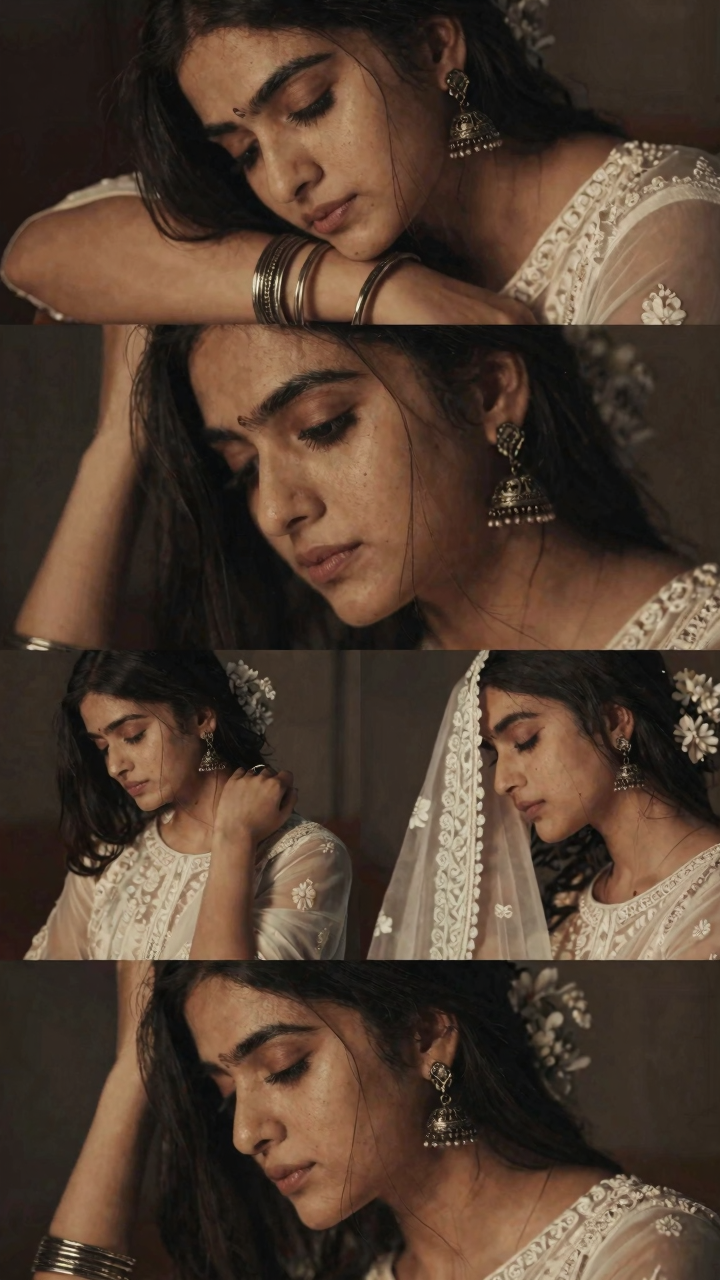

In [10]:
#@title 3. Creator Studio
#@markdown Enter your prompt and settings to generate images.

#@markdown ### 🎨 **Prompting**
positive_prompt = "Moody Traditional Indian Girl Portrait Collage  Create an ultra-realistic, cinematic 4-panel editorial photo collage featuring a young South Asian woman, inspired by the uploaded reference image. Maintain a consistent appearance, facial identity, hairstyle, outfit, jewellery, lighting, and color grading across all panels.  Layout & Composition: A vertical 2:3 collage consisting of five cinematic photographic sections arranged like an aesthetic Pinterest mood board:  - Top panel: Extreme close-up side profile with eyes gently closed, face resting near a raised forearm, delicate silver bangles visible on the wrist. - Second panel: Extreme close-up of expressive dark eyes, natural eyebrows, subtle eyeliner, and loose strands of hair framing the face. - Middle-left panel: Three-quarter side portrait with head tilted downward, eyes closed, one hand gently touching the hair. - Middle-right panel: Intimate side close-up with the face partially hidden behind a sheer embroidered sleeve, eyes closed in a peaceful expression. - Bottom panel: Close-up side profile showing the nose, lips, cheek, loose hair strands, and intricate traditional earring.  Subject & Appearance: A young South Asian woman with naturally dark hair loosely tied back, a soft white floral hair accessory, delicate facial features, realistic skin texture, and a calm, introspective expression. A few fine strands of hair fall naturally across her forehead and cheeks.  Outfit & Jewellery: An elegant ivory-white traditional outfit with sheer fabric, delicate floral embroidery, and subtle lace detailing. Antique silver jhumka earrings with intricate filigree work and tiny dangling beads. Multiple thin oxidized-silver bangles on one wrist. Keep the styling traditional, understated, and elegant.  Expressions & Poses: Soft, candid expressions with eyes gently closed in most panels. In the eye close-up, the subject looks slightly sideways. Natural hand placement, relaxed shoulders, gently tilted head, and delicate interaction between the face, sleeve, and forearm.  Lighting & Color Palette: Warm, dim cinematic lighting with soft amber highlights on the skin and jewellery. Deep charcoal shadows, a dark neutral background, muted earthy tones, subtle highlights on the eyes, and a gentle film-like glow. Avoid harsh lighting and excessive skin smoothing.  Photography Style: Ultra-realistic close-up portrait photography, 85mm portrait lens, shallow depth of field, realistic skin pores, fine hair strands, detailed embroidered fabric, sharp jewellery textures, natural facial proportions, soft film grain, and premium editorial color grading.  Technical Specifications:  - Aspect ratio: 2:3 vertical - Resolution: 4K to 8K - Style: Photorealistic, cinematic, moody, traditional Indian editorial - Collage borders: Clean, straight horizontal and vertical divisions - Consistency: Same person, same outfit, same hairstyle, same jewellery, same lighting across all panels  Negative Prompt: Cartoon, illustration, CGI, plastic skin, excessive beauty filters, distorted eyes, asymmetrical facial errors, deformed hands, extra fingers, duplicate face, inconsistent jewellery, changing outfits, oversaturated colors, harsh flash, blurry details, text, watermark, logo.  Final Goal: A cohesive, intimate, cinematic traditional portrait collage with expressive close-ups, delicate silver jewellery, soft ivory embroidery, and warm moody lighting." # @param {type:"string"}
negative_prompt = "blurry, low quality, text, watermark, distorted" # @param {type:"string"}

#@markdown ### 📐 **Dimensions & Quality**
aspect_ratio = "720x1280 (9:16 Portrait)" # @param ["1024x1024 (1:1 Square)", "1280x720 (16:9 Landscape)", "720x1280 (9:16 Portrait)", "1152x864 (4:3 Photo)", "1344x576 (21:9 Cinema)"]
steps = 50 # @param {type:"slider", min:10, max:50, step:1}
guidance_scale = 1 # @param {type:"slider", min:1.0, max:10.0, step:0.5}

#@markdown ### ⚙️ **Advanced**
seed = 1222102321431113233 # @param {type:"number"}
auto_download = False # @param {type:"boolean"}

# Parse Inputs
w, h = [int(x) for x in aspect_ratio.split("(")[0].strip().split("x")]
gen_seed = torch.randint(0, 2**63 - 1, (1,)).item() if seed == -1 else seed

try:
    flush_mem()
    print(f"\033[94m➜ Generating: {w}x{h} | Steps: {steps} | Seed: {gen_seed}\033[0m")

    # IMPORTANT: Use inference_mode to avoid tensor version errors during decoding
    with torch.inference_mode():
        # Encode
        pos_enc = nodes["enc"].encode(clip_model, positive_prompt)[0]
        neg_enc = nodes["enc"].encode(clip_model, negative_prompt)[0]
        latent = nodes["empty"].generate(w, h, batch_size=1)[0]

        # Sample
        sample = nodes["sampler"].sample(
            unet_model, gen_seed, steps, guidance_scale,
            "euler", "simple", pos_enc, neg_enc, latent, denoise=1.0
        )[0]

        # Decode
        decoded = nodes["decode"].decode(vae_model, sample)[0].detach()

    # Save & Show
    img_out = Image.fromarray(np.array(decoded * 255, dtype=np.uint8)[0])
    save_path = get_save_path(positive_prompt)
    img_out.save(save_path)

    print(f"\033[92m✓ Saved to: {save_path.name}\033[0m")
    display(img_out)

    if auto_download:
        from google.colab import files
        files.download(str(save_path))

except NameError:
    log("Engine not loaded. Please run Step 2.", "error")
except Exception as e:
    log(f"Error: {e}", "error")